# QMIX на Simple Spread: обучение, сохранение и запуск модели

[![Открыть в Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kite121/qmix-simple-spread/blob/karimkhab/notebooks/qmix_simple_spread.ipynb)

Часть Карима в командном проекте. Что делает этот notebook:

1. показывает среду Simple Spread в том виде, в каком её видит QMIX;
2. показывает, **где считаются оценки каждого агента $Q_i$**, **как они объединяются в общую оценку команды $Q_{tot}$**, **как считается TD-цель** и **какая ошибка уменьшается**;
3. разбирает один **полностью числовой пример TD-обновления**;
4. **обучает QMIX с нуля**, **сохраняет модель** и строит **график награды**;
5. **загружает сохранённую модель** и проигрывает эпизод **без дообучения**.

**Запуск в Colab:** «Среда выполнения» → «Выполнить все». GPU не нужен: сети маленькие, на процессоре быстрее.
Полное обучение (200 000 шагов среды) заняло 5 минут на одном ядре процессора; в Colab ожидаем 5–10 минут. Чтобы только проверить, что всё запускается, поставьте `QUICK_CHECK = True` (около 2 минут, модель при этом почти не обучится).

Код алгоритма лежит в репозитории в `src/qmix_spread/`. Notebook скачивает его и показывает ключевые функции прямо здесь. Подробный отчёт с числами: `results/qmix_training_report.md`.

## 0. Настройки

In [1]:
QUICK_CHECK = False  # True: tiny run (about 2 minutes) only to check that every cell works
BRANCH = "karimkhab"  # repository branch with the code; change to "main" after the merge
SEED = 0  # training seed of the main run

## 1. Установка и код проекта

Если notebook открыт в Colab, скачиваем репозиторий. Если он открыт внутри уже скачанного репозитория, берём код оттуда. Затем ставим библиотеки среды с точными версиями из `requirements.txt`.

In [2]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/kite121/qmix-simple-spread.git"
if os.path.isdir("../src/qmix_spread"):  # opened inside a clone of the repository
    REPO_DIR = os.path.abspath("..")
else:  # Google Colab: download the code first
    REPO_DIR = os.path.abspath("qmix-simple-spread")
    if not os.path.isdir(REPO_DIR):
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPO_URL, REPO_DIR], check=True)
sys.path.insert(0, os.path.join(REPO_DIR, "src"))
print("code from:", REPO_DIR)

code from: /home/user/qmix-simple-spread


In [3]:
%pip install -q -r {REPO_DIR}/requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [4]:
import inspect

import numpy as np
import torch
from IPython.display import Code, Image, Markdown, display

from qmix_spread.checkpoint import build_networks, library_versions, load_checkpoint
from qmix_spread.config import QMIXConfig
from qmix_spread.env import ACTION_NAMES, SpreadEnv
from qmix_spread.learner import QMIXLearner, unroll_agent_network
from qmix_spread.networks import AgentNetwork, QMixer
from qmix_spread.plotting import plot_episode_trajectories
from qmix_spread.rollout import QMIXPolicy, RandomPolicy, evaluate, run_episode
from qmix_spread.td_example import (
    check_with_autograd,
    episodes_to_batch,
    format_hand_example,
    format_real_example,
    hand_td_example,
    real_transition_example,
)
from qmix_spread.train import random_baseline, save_run, train

torch.set_num_threads(1)  # tiny networks: one thread is as fast and keeps the run reproducible


def show_source(obj):
    # Shows the code of a class or function from src/qmix_spread right in the notebook.
    display(Code(inspect.getsource(obj), language="python"))


for name, value in library_versions().items():
    print(f"{name:>10}: {value}")

    python: 3.13.16
     torch: 2.14.1+cpu
     numpy: 2.5.3
      mpe2: 1.1.1
pettingzoo: 1.27.0
 gymnasium: 1.4.0


## 2. Среда Simple Spread

| Параметр | Значение | Смысл |
| --- | --- | --- |
| `N` | 2 | 2 агента и 2 точки-ориентира |
| `local_ratio` | 0 | только общая награда команды, у обоих агентов она одинаковая |
| `continuous_actions` | False | 5 дискретных действий: стоять, влево, вправо, вниз, вверх |
| `max_cycles` | 25 | эпизод длится 25 шагов |

**Цель агентов:** вдвоём накрыть обе точки — к каждой точке должен подойти хотя бы один агент.

**Награда за шаг** (одна на команду) = −(расстояние от точки 1 до ближайшего агента + расстояние от точки 2 до ближайшего агента). Чем ближе агенты к точкам, тем ближе награда к нулю. При `local_ratio=0` штраф за столкновения агентов в награду не входит: он относится к «локальной» части награды.

**Наблюдение агента** — 12 чисел, только то, что видит он сам. **Полное состояние** — наблюдения обоих агентов подряд, 24 числа. Его видит только смешивающая сеть при обучении.

Параметры взяты из задания. Когда Женя выложит свою часть, их нужно сверить с его notebook.

In [5]:
config = QMIXConfig(seed=SEED)
if QUICK_CHECK:
    config.total_env_steps = 5_000
    config.eval_interval_steps = 2_500

env = SpreadEnv(config)
print(f"agents: {env.n_agents}, actions per agent: {env.n_actions} {ACTION_NAMES}")
print(f"observation of one agent: {env.obs_dim} numbers, full state: {env.state_dim} numbers")

obs, state = env.reset(seed=30_000)  # seed fixes the start positions
parts = [("own velocity", 0, 2), ("own position", 2, 4), ("landmark 1, relative", 4, 6),
         ("landmark 2, relative", 6, 8), ("other agent, relative", 8, 10), ("communication (unused)", 10, 12)]
for i in range(env.n_agents):
    print(f"\nagent {i + 1} observation:")
    for label, start, end in parts:
        print(f"  {label:<24} {obs[i, start:end].round(3)}")
print("\nfull state == both observations one after another:", np.allclose(state, obs.reshape(-1)))

# One step: agent 1 goes up, agent 2 goes left. SpreadEnv.step checks that both rewards are equal.
next_obs, next_state, reward, terminated, truncated = env.step(np.array([4, 1]))
print(f"after one step: team reward {reward:.4f}, terminated={terminated}, truncated={truncated}")

agents: 2, actions per agent: 5 ['no_action', 'move_left', 'move_right', 'move_down', 'move_up']
observation of one agent: 12 numbers, full state: 24 numbers

agent 1 observation:
  own velocity             [0. 0.]
  own position             [-0.399  0.231]
  landmark 1, relative     [-0.256 -0.44 ]
  landmark 2, relative     [ 0.655 -0.628]
  other agent, relative    [-0.369 -0.446]
  communication (unused)   [0. 0.]

agent 2 observation:
  own velocity             [0. 0.]
  own position             [-0.768 -0.215]
  landmark 1, relative     [0.113 0.006]
  landmark 2, relative     [ 1.024 -0.182]
  other agent, relative    [0.369 0.446]
  communication (unused)   [0. 0.]

full state == both observations one after another: True
after one step: team reward -1.0203, terminated=False, truncated=False


## 3. Идея QMIX

* **Сеть агента** считает $Q_i(\text{история агента } i, a)$ — насколько хорошо агенту $i$ сделать действие $a$. На входе только его собственное наблюдение, его прошлое действие и номер агента. Сеть одна на двоих (общие веса).
* **Смешивающая сеть** берёт $Q_i$ выбранных действий обоих агентов и складывает их в $Q_{tot}$ — оценку всей команды. Веса смешивания зависят от **полного состояния** $s$ и всегда **неотрицательны**. Значит, $\partial Q_{tot} / \partial Q_i \ge 0$: если оценка любого агента растёт, общая оценка не падает. Это и есть **условие монотонности**.
* **Обучение:** у команды одна общая награда, поэтому учим $Q_{tot}$ по TD-ошибке. Сети агентов учатся через смешивающую сеть.
* **Выполнение:** смешивающая сеть больше не нужна. Каждый агент берёт действие с наибольшим $Q_i$. Из-за монотонности это совместное действие даёт и наибольшее $Q_{tot}$.

| Часть | При обучении | При выполнении политики |
| --- | --- | --- |
| Сеть агента → $Q_i$ | да | да |
| Смешивающая сеть → $Q_{tot}$ | да | нет |
| Полное состояние $s$ | да (вход смешивающей сети) | нет |
| Целевые копии сетей (для TD-цели) | да | нет |

## 4. Где считаются $Q_i$ — сеть агента

Вход: 12 чисел наблюдения + 5 чисел прошлого действия (one-hot) + 2 числа номера агента = 19. Дальше Linear → ReLU → GRU (память о прошлых шагах эпизода) → Linear. На выходе 5 чисел: $Q_i$ для каждого действия. Ниже код класса из `src/qmix_spread/networks.py` и его запуск на настоящем наблюдении.

In [6]:
show_source(AgentNetwork)

class AgentNetwork(nn.Module):
    """Computes Q_i: one value per action for every agent.

    This is the DRQN agent from the QMIX paper:
        input  = [own observation, own previous action (one-hot), agent id (one-hot)]
        layers = Linear -> ReLU -> GRU cell -> Linear
        output = Q_i(history_i, a) for each of the A actions

    One set of weights is shared by all agents (faster learning). The agent id in the
    input still lets the network behave differently for different agents if that helps.
    The GRU keeps a memory (hidden state) of what this agent has seen so far in the episode.
    """

    def __init__(self, obs_dim: int, n_agents: int, n_actions: int, hidden_dim: int):
        super().__init__()
        self.obs_dim = obs_dim
        self.n_agents = n_agents
        self.n_actions = n_actions
        self.hidden_dim = hidden_dim
        input_dim = obs_dim + n_actions + n_agents  # 12 + 5 + 2 = 19 for Simple Spread N=2

        self.fc_in = nn.Linear(input_dim, hidden_dim)
        self.gru = nn.GRUCell(hidden_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, n_actions)

    def init_hidden(self, batch_size: int) -> torch.Tensor:
        """Empty memory at the start of an episode: zeros [B, n, H]."""
        return torch.zeros(batch_size, self.n_agents, self.hidden_dim)

    def forward(
        self, obs: torch.Tensor, last_actions_onehot: torch.Tensor, hidden: torch.Tensor
    ) -> tuple[torch.Tensor, torch.Tensor]:
        """One time step for all agents at once.

        obs                 [B, n, O]
        last_actions_onehot [B, n, A]  (all zeros at the first step of an episode)
        hidden              [B, n, H]
        returns q [B, n, A] and the new hidden [B, n, H]
        """
        batch_size = obs.shape[0]

        # One-hot agent ids, the same for every episode in the batch.
        # torch.eye(2) = [[1, 0],      agent 0
        #                 [0, 1]]      agent 1
        # .expand(B, -1, -1) repeats this [n, n] matrix B times without copying memory -> [B, n, n]
        agent_ids = torch.eye(self.n_agents).expand(batch_size, -1, -1)

        # Glue the three parts along the last axis: [B, n, O + A + n]
        inputs = torch.cat([obs, last_actions_onehot, agent_ids], dim=-1)

        # Weights are shared, so every (episode, agent) pair is just one more row.
        # reshape [B, n, 19] -> [B*n, 19]; e.g. B=3, n=2 gives 6 rows:
        #   row 0 = episode 0 agent 0, row 1 = episode 0 agent 1, row 2 = episode 1 agent 0, ...
        x = inputs.reshape(batch_size * self.n_agents, -1)
        h = hidden.reshape(batch_size * self.n_agents, self.hidden_dim)

        x = F.relu(self.fc_in(x))  # [B*n, H]
        h = self.gru(x, h)  # [B*n, H]  memory updated with the current input
        q = self.fc_out(h)  # [B*n, A]  <- the individual Q_i values

        # Back to one row per episode and one slot per agent.
        return q.view(batch_size, self.n_agents, self.n_actions), h.view(
            batch_size, self.n_agents, self.hidden_dim
        )

In [7]:
torch.manual_seed(SEED)
agent_net, mixer = build_networks(config, env)  # untrained: random weights

obs, state = env.reset(seed=30_000)
obs_t = torch.as_tensor(obs).unsqueeze(0)  # [1, n, O] = [1, 2, 12]
no_last_action = torch.zeros(1, env.n_agents, env.n_actions)  # first step: no previous action
q, hidden = agent_net(obs_t, no_last_action, agent_net.init_hidden(1))
print("input:", tuple(obs_t.shape), "+", tuple(no_last_action.shape), " ->  Q:", tuple(q.shape), " memory:", tuple(hidden.shape))
for i in range(env.n_agents):
    values = ", ".join(f"{name} {v:+.3f}" for name, v in zip(ACTION_NAMES, q[0, i].tolist()))
    print(f"Q_{i + 1}: {values}")
print("(the network is not trained yet, so the values are small and mean nothing)")

input: (1, 2, 12) + (1, 2, 5)  ->  Q: (1, 2, 5)  memory: (1, 2, 64)
Q_1: no_action -0.030, move_left +0.046, move_right -0.010, move_down +0.004, move_up -0.176
Q_2: no_action -0.028, move_left -0.001, move_right -0.034, move_down -0.007, move_up -0.156
(the network is not trained yet, so the values are small and mean nothing)


## 5. Как $Q_i$ объединяются в $Q_{tot}$ — смешивающая сеть

$$\text{hidden} = \mathrm{ELU}(Q_{agents} \cdot W_1 + b_1), \qquad Q_{tot} = \text{hidden} \cdot W_2 + b_2,$$

где $W_1$ (2×32), $b_1$, $W_2$ (32×1), $b_2$ выдают маленькие **гиперсети** по полному состоянию $s$. К $W_1$ и $W_2$ применяется модуль, поэтому они не бывают отрицательными.

**Наше добавление (в статье его нет).** Перед гиперсетями состояние проходит через мягкий ограничитель $3 \cdot \tanh(s/3)$. У Simple Spread нет стен, агенты могут уехать сколь угодно далеко, а гиперсети линейны по $s$. В пробных запусках без ограничителя сеть оценивала далёкие состояния как очень хорошие ($Q_{tot}$ до +600, хотя все награды отрицательные), и агенты учились уезжать. Для обычных значений ограничитель почти ничего не меняет (1 → 0.96), а далёкие ограничивает значением ±3. Монотонность по $Q_i$ он не затрагивает.

In [8]:
show_source(QMixer)

class QMixer(nn.Module):
    """Mixes the chosen Q_i of all agents into one team value Q_tot, using the full state.

        hidden = ELU(Q_agents . W1 + b1)      W1 [n, E] >= 0, b1 [E]
        Q_tot  = hidden . W2 + b2             W2 [E, 1] >= 0, b2 scalar

    W1, b1, W2, b2 are not fixed parameters: small "hypernetworks" produce them from the
    full state s, so the way agents are combined can change from situation to situation.
    W1 and W2 pass through abs(), so they are never negative. ELU is an increasing function.
    Together this gives monotonicity: if any Q_i goes up, Q_tot cannot go down.
    That is why each agent can simply take its own best action at execution time:
    the joint action made of individual best actions is also the best for Q_tot.

    The state is used only here, i.e. only during training.
    """

    def __init__(self, n_agents: int, state_dim: int, embed_dim: int, state_limit: float):
        super().__init__()
        self.n_agents = n_agents
        self.state_dim = state_dim
        self.embed_dim = embed_dim
        self.state_limit = state_limit

        # Hypernetworks for the weights: one linear layer each, as in the paper.
        self.hyper_w1 = nn.Linear(state_dim, n_agents * embed_dim)
        self.hyper_w2 = nn.Linear(state_dim, embed_dim)
        # Hypernetworks for the biases. Biases may be negative, so no abs() here.
        self.hyper_b1 = nn.Linear(state_dim, embed_dim)
        # The final bias V(s) is a small two-layer network, as in the paper.
        self.hyper_b2 = nn.Sequential(
            nn.Linear(state_dim, embed_dim), nn.ReLU(), nn.Linear(embed_dim, 1)
        )

    def forward(self, agent_qs: torch.Tensor, states: torch.Tensor) -> torch.Tensor:
        """agent_qs [..., n] (one chosen Q_i per agent), states [..., S]  ->  Q_tot [...].

        Any leading shape works, e.g. [B, T] for a batch of whole episodes.
        """
        leading_shape = agent_qs.shape[:-1]
        qs = agent_qs.reshape(-1, 1, self.n_agents)  # [N, 1, n]  N = all leading dims flattened
        s = states.reshape(-1, self.state_dim)  # [N, S]

        # Soft limit of the state values: limit * tanh(s / limit). With limit = 3:
        #   0.5 -> 0.50,  1.0 -> 0.96,  2.0 -> 1.75,  5.0 -> 2.79,  50.0 -> 3.00
        # Simple Spread has no walls, so agents can wander far from the area where they start.
        # The hypernetworks are linear in s; without a limit they produce huge mixing weights for
        # such far states, Q_tot runs away, and the agents learn to run away too (see the report).
        s = self.state_limit * torch.tanh(s / self.state_limit)

        # First layer weights, generated from the state and made non-negative.
        w1 = torch.abs(self.hyper_w1(s)).view(-1, self.n_agents, self.embed_dim)  # [N, n, E]
        b1 = self.hyper_b1(s).view(-1, 1, self.embed_dim)  # [N, 1, E]

        # torch.bmm = one matrix product per row of the batch: [N, 1, n] x [N, n, E] -> [N, 1, E]
        # Example for one row with n=2, E=3:
        #   qs = [[2.0, 1.0]]   w1 = [[0.5, 0.1, 0.0],
        #                             [0.2, 0.3, 1.0]]
        #   qs @ w1 = [[2*0.5 + 1*0.2, 2*0.1 + 1*0.3, 2*0.0 + 1*1.0]] = [[1.2, 0.5, 1.0]]
        # Each hidden unit is a weighted sum of the agents' Q values with non-negative weights.
        hidden = F.elu(torch.bmm(qs, w1) + b1)  # [N, 1, E]

        # Second layer: E hidden units -> one number.
        w2 = torch.abs(self.hyper_w2(s)).view(-1, self.embed_dim, 1)  # [N, E, 1]
        b2 = self.hyper_b2(s).view(-1, 1, 1)  # [N, 1, 1]
        q_tot = torch.bmm(hidden, w2) + b2  # [N, 1, E] x [N, E, 1] -> [N, 1, 1]

        return q_tot.view(leading_shape)

In [9]:
best_q = q[0].max(dim=1).values.unsqueeze(0)  # [1, n]: Q of each agent's best action
state_t = torch.as_tensor(state).unsqueeze(0)  # [1, S] = [1, 24]
q_tot = mixer(best_q, state_t)
w1 = torch.abs(mixer.hyper_w1(state_t)).view(env.n_agents, config.mixing_embed_dim)
w2 = torch.abs(mixer.hyper_w2(state_t))
print(f"Q_1, Q_2 = {best_q[0].tolist()}  ->  Q_tot = {q_tot.item():.4f}")
print(f"W1: shape {tuple(w1.shape)}, smallest entry {w1.min():.4f} (never negative)")
print(f"W2: shape {tuple(w2.shape)}, smallest entry {w2.min():.4f} (never negative)")

# Monotonicity checked with numbers: dQ_tot/dQ_i >= 0 on 1000 random inputs.
random_qs = (torch.randn(1000, env.n_agents) * 20).requires_grad_(True)
random_states = torch.randn(1000, env.state_dim) * 2
mixer(random_qs, random_states).sum().backward()
print(f"smallest dQ_tot/dQ_i over 1000 random inputs: {random_qs.grad.min():.5f}  (>= 0)")

Q_1, Q_2 = [0.04563869535923004, -0.001185055822134018]  ->  Q_tot = -0.0028
W1: shape (2, 32), smallest entry 0.0012 (never negative)
W2: shape (1, 32), smallest entry 0.0162 (never negative)
smallest dQ_tot/dQ_i over 1000 random inputs: 0.00000  (>= 0)


**Почему агенты могут действовать сами по себе.** Переберём все 5 × 5 = 25 совместных действий и посчитаем $Q_{tot}$ для каждого. Наибольшее значение (выделено) получается ровно там, где каждый агент выбрал своё лучшее действие. Это следует из монотонности и верно при любых весах. Здесь сеть ещё не обучена, поэтому числа отличаются только в четвёртом знаке.

In [10]:
def joint_action_table(agent_q, mixer, state_t):
    # agent_q [n, A] for n = 2 agents -> Markdown table of Q_tot for all 5 x 5 joint actions.
    table = torch.zeros(env.n_actions, env.n_actions)
    with torch.no_grad():
        for a1 in range(env.n_actions):
            for a2 in range(env.n_actions):
                table[a1, a2] = mixer(torch.stack([agent_q[0, a1], agent_q[1, a2]]).unsqueeze(0), state_t)
    best = divmod(int(table.argmax()), env.n_actions)
    lines = ["| агент 1 \\ агент 2 | " + " | ".join(ACTION_NAMES) + " |", "|---" * (env.n_actions + 1) + "|"]
    for a1 in range(env.n_actions):
        cells = [f"**{v:.4f}**" if (a1, a2) == best else f"{v:.4f}" for a2, v in enumerate(table[a1].tolist())]
        lines.append(f"| {ACTION_NAMES[a1]} | " + " | ".join(cells) + " |")
    return "\n".join(lines), best

table_md, best_joint = joint_action_table(q[0].detach(), mixer, state_t)
display(Markdown(table_md))
best_individual = tuple(int(a) for a in q[0].argmax(dim=1))
print("best joint action:", [ACTION_NAMES[a] for a in best_joint])
print("each agent's own best action:", [ACTION_NAMES[a] for a in best_individual])
print("the same:", best_joint == best_individual)

| агент 1 \ агент 2 | no_action | move_left | move_right | move_down | move_up |
|---|---|---|---|---|---|
| no_action | -0.0941 | -0.0716 | -0.0992 | -0.0763 | -0.1996 |
| move_left | -0.0254 | **-0.0028** | -0.0306 | -0.0076 | -0.1317 |
| move_right | -0.0765 | -0.0540 | -0.0817 | -0.0587 | -0.1822 |
| move_down | -0.0635 | -0.0410 | -0.0687 | -0.0457 | -0.1694 |
| move_up | -0.2260 | -0.2038 | -0.2310 | -0.2084 | -0.3300 |

best joint action: ['move_left', 'move_left']
each agent's own best action: ['move_left', 'move_left']
the same: True


## 6. TD-цель и ошибка, которую минимизируем

Для каждого шага $t$ каждого эпизода в батче (32 эпизода × 25 шагов):

* текущая оценка: $Q_{tot}(s_t, a_t)$ — сеть агентов и смешивающая сеть на действиях, которые агенты реально сделали;
* **TD-цель:** $y_t = r_t + \gamma \cdot Q^{-}_{tot}(s_{t+1}, \text{лучшие действия агентов в } s_{t+1})$, где $Q^{-}$ — **целевые копии** сетей, они обновляются раз в 200 эпизодов;
* **TD-ошибка:** $\delta_t = y_t - Q_{tot}(s_t, a_t)$;
* **минимизируем** среднее $\delta_t^2$ по всем шагам батча. Градиент идёт и в смешивающую сеть, и в сеть агентов.

Лучшие действия в $s_{t+1}$ выбирает обучаемая сеть, а оценивает их целевая копия (Double Q-learning, как в эталонном коде авторов QMIX). Так оценка меньше завышается. Окончание эпизода по лимиту 25 шагов не считается концом задачи: агент не видит номер шага, поэтому следующую оценку не обнуляем.

Коэффициент дисконтирования $\gamma = 0.95$ (в статье 0.99). Эпизод длится всего 25 шагов, и горизонта примерно в 20 шагов хватает. При 0.99 в пробных запусках оценки медленно уходили в положительную область и обучение разваливалось (подробности в отчёте).

Ниже код из `src/qmix_spread/learner.py` и его запуск на 4 случайных эпизодах. Видны размеры всех промежуточных тензоров.

In [11]:
show_source(QMIXLearner.compute_td_loss)

def compute_td_loss(self, batch: dict[str, torch.Tensor]) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        """Squared TD error of Q_tot, averaged over all episodes and steps of the batch.

        Batch (from EpisodeBuffer.sample): obs [B, T+1, n, O], state [B, T+1, S],
        actions [B, T, n], reward [B, T], terminated [B, T].
        Returns the loss and the intermediate tensors (used by the numeric example).
        """
        obs, state, actions = batch["obs"], batch["state"], batch["actions"]
        reward, terminated = batch["reward"], batch["terminated"]

        # 1) Individual Q_i of every agent, for every action, at every step.
        q_all = unroll_agent_network(self.agent_net, obs, actions)  # [B, T+1, n, A]

        # Keep only the Q value of the action each agent actually took at steps 0..T-1.
        # gather picks, along the action axis (dim 3), the entry whose index is in `actions`:
        #   Q of one agent at one step = [0.1, 0.7, -0.2, 0.0, 0.3], action taken = 1  ->  0.7
        # actions.unsqueeze(-1) adds the axis gather needs: [B, T, n] -> [B, T, n, 1].
        chosen_q = torch.gather(q_all[:, :-1], dim=3, index=actions.unsqueeze(-1)).squeeze(-1)  # [B, T, n]

        # 2) Mix the agents' chosen Q_i into the team value Q_tot, using the full state.
        q_tot = self.mixer(chosen_q, state[:, :-1])  # [B, T]

        # 3) TD target y = r + gamma * Q_tot_target(next step, best joint action).
        with torch.no_grad():  # the target is a fixed number for this step, no gradient through it
            target_q_all = unroll_agent_network(self.target_agent_net, obs, actions)  # [B, T+1, n, A]
            # Value of every agent's best action at the next step (steps 1..T).
            # Because the mixer is monotonic, "every agent takes its own best action" gives the
            # best joint action for Q_tot as well, so we never need to try all 5 x 5 combinations.
            if self.double_q:
                # Double Q-learning: the online network picks the action, the target network rates it.
                # A single network that both picks and rates the max tends to overestimate.
                next_actions = q_all[:, 1:].argmax(dim=3, keepdim=True)  # [B, T, n, 1]
                target_max_q = torch.gather(target_q_all[:, 1:], dim=3, index=next_actions).squeeze(3)  # [B, T, n]
            else:
                target_max_q = target_q_all[:, 1:].max(dim=3).values  # [B, T, n]
            target_q_tot = self.target_mixer(target_max_q, state[:, 1:])  # [B, T]
            # (1 - terminated) drops the future only if the task itself ended. The 25-step time
            # limit is not such an end: the agents cannot see the step counter, so we still
            # bootstrap from the next state (Pardo et al., 2018, "Time Limits in RL").
            td_target = reward + self.gamma * (1.0 - terminated) * target_q_tot  # [B, T]

        # 4) TD error and the loss that is minimised: mean of squared TD errors.
        td_error = td_target - q_tot  # [B, T]  > 0 means "better than the network expected"
        loss = (td_error**2).mean()

        details = {
            "q_all": q_all,
            "chosen_q": chosen_q,
            "q_tot": q_tot,
            "target_max_q": target_max_q,
            "target_q_tot": target_q_tot,
            "td_target": td_target,
            "td_error": td_error,
        }
        return loss, details

In [12]:
rng = np.random.default_rng(0)
random_agents = RandomPolicy(env.n_agents, env.n_actions)
episodes = [run_episode(env, random_agents, seed=40_000 + k, rng=rng) for k in range(4)]
batch = episodes_to_batch(episodes)
learner = QMIXLearner(agent_net, mixer, config)
loss, details = learner.compute_td_loss(batch)

print("batch (B episodes, T = 25 steps, n = 2 agents):")
for key, value in batch.items():
    print(f"  {key:<11} {tuple(value.shape)}")
print("intermediate tensors:")
for key, value in details.items():
    print(f"  {key:<14} {tuple(value.shape)}")
print(f"loss = mean(td_error ** 2) = {loss.item():.4f}")

batch (B episodes, T = 25 steps, n = 2 agents):
  obs         (4, 26, 2, 12)
  state       (4, 26, 24)
  actions     (4, 25, 2)
  reward      (4, 25)
  terminated  (4, 25)
intermediate tensors:
  q_all          (4, 26, 2, 5)
  chosen_q       (4, 25, 2)
  q_tot          (4, 25)
  target_max_q   (4, 25, 2)
  target_q_tot   (4, 25)
  td_target      (4, 25)
  td_error       (4, 25)
loss = mean(td_error ** 2) = 2.4277


## 7. Числовой пример TD-обновления (руками)

Чтобы всё можно было пересчитать на бумаге, смешивающая сеть здесь однослойная: $Q_{tot} = w_1 Q_1 + w_2 Q_2 + b$, причём $w_1, w_2 \ge 0$. В настоящей сети есть скрытый слой, а $w$ и $b$ выдают гиперсети по состоянию, но сам TD-шаг устроен так же. Шаг 0.005 взят крупным, чтобы изменение было заметно (при обучении 0.0005).

In [13]:
example = hand_td_example()
display(Markdown(format_hand_example(example)))
autograd = check_with_autograd(example)
print(f"PyTorch autograd recomputed every number; largest difference: {autograd['max_abs_difference']:.2e}")

| Шаг | Формула | Значение |
| --- | --- | --- |
| Дано: награда за шаг r |  | -1 |
| Дано: коэффициент дисконтирования γ |  | 0.95 |
| Дано: оценки агентов для выбранных действий Q₁, Q₂ |  | -4.0, -6.0 |
| Дано: веса смешивания для текущего состояния w₁, w₂, b |  | 0.5, 1.0, -2.0 |
| 1. Текущая общая оценка Q_tot | w₁·Q₁ + w₂·Q₂ + b | -10 |
| 2. Лучшая оценка агента 1 в следующем шаге | max[-6.0, -5.5, -5.0, -7.0, -6.5] | -5 |
| 2. Лучшая оценка агента 2 в следующем шаге | max[-3.0, -2.5, -4.0, -3.5, -2.8] | -2.5 |
| 2. Следующая общая оценка Q_tot′ (веса следующего состояния 0.8, 0.4, -3.0) | w₁′·maxQ₁′ + w₂′·maxQ₂′ + b′ | -8 |
| 3. TD-цель y | r + γ·Q_tot′ | -8.6 |
| 3. TD-ошибка δ | y − Q_tot | 1.4 |
| 3. Ошибка, которую минимизируем | δ² | 1.96 |
| 4. Градиент по Q_tot | −2·δ | -2.8 |
| 4. Сигнал агенту 1 | −2·δ·w₁ | -1.4 |
| 4. Сигнал агенту 2 | −2·δ·w₂ | -2.8 |
| 4. Градиенты по w₁, w₂, b | −2·δ·Q₁, −2·δ·Q₂, −2·δ | 11.2, 16.8, -2.8 |
| 5. Шаг с размером 0.005: новые w₁, w₂, b | параметр − шаг·градиент | 0.4440, 0.9160, -1.9860 |
| 5. Новая общая оценка Q_tot | новые w₁·Q₁ + w₂·Q₂ + b | -9.258 |
| 5. Новая TD-ошибка | y − новая Q_tot | 0.658 |

PyTorch autograd recomputed every number; largest difference: 0.00e+00


**Как читать.** Сеть ожидала $Q_{tot} = -10$, а по факту получилось лучше: награда $-1$ плюс дисконтированная оценка следующего шага ($0.95 \cdot (-8) = -7.6$) дают TD-цель $-8.6$. Ошибка положительная ($+1.4$), значит $Q_{tot}$ нужно поднять. Один градиентный шаг меняет веса так, что $Q_{tot}$ становится $-9.258$, и ошибка уменьшается примерно вдвое ($1.4 \to 0.658$). Агент 2 получает вдвое больший сигнал, чем агент 1, потому что его вес смешивания вдвое больше ($w_2 = 1.0$ против $w_1 = 0.5$). Так смешивающая сеть распределяет между агентами «заслугу» за общую награду.

В нашем коде лучшее действие в следующем шаге выбирает обучаемая сеть, а оценивает целевая (Double Q). В этом примере они совпадают, поэтому «лучшее» — просто максимум.

## 8. Обучение с нуля

Все параметры запуска (они же сохраняются внутри checkpoint):

In [14]:
rows = "\n".join(f"| `{key}` | {value} |" for key, value in config.to_dict().items())
display(Markdown("| Параметр | Значение |\n| --- | --- |\n" + rows))

| Параметр | Значение |
| --- | --- |
| `n_agents` | 2 |
| `local_ratio` | 0.0 |
| `max_cycles` | 25 |
| `agent_hidden_dim` | 64 |
| `mixing_embed_dim` | 32 |
| `mixer_state_limit` | 3.0 |
| `gamma` | 0.95 |
| `double_q` | True |
| `lr` | 0.0005 |
| `rmsprop_alpha` | 0.99 |
| `rmsprop_eps` | 1e-05 |
| `grad_clip_norm` | 10.0 |
| `batch_size` | 32 |
| `buffer_size` | 5000 |
| `target_update_interval` | 200 |
| `epsilon_start` | 1.0 |
| `epsilon_finish` | 0.05 |
| `epsilon_anneal_steps` | 50000 |
| `total_env_steps` | 200000 |
| `seed` | 0 |
| `eval_interval_steps` | 10000 |
| `eval_seeds_start` | 10000 |
| `n_eval_episodes` | 32 |

Каждые `eval_interval_steps` шагов печатается строка. В ней средняя награда последних 100 обучающих эпизодов (с исследованием), награда обученной политики **без случайных действий** на 32 фиксированных начальных расстановках, средняя TD-ошибка и средняя $Q_{tot}$.

In [15]:
result = train(config)
print(f"\ndone: {result.env_steps} env steps, {result.episodes} episodes, {result.wall_time_sec / 60:.1f} min")

steps       0 | episodes      0 | epsilon 1.00 | train return (last 100)     nan | greedy eval  -82.88 +- 30.49 | loss      nan | Q_tot      nan |      0 s


steps   10000 | episodes    400 | epsilon 0.81 | train return (last 100)  -39.83 | greedy eval  -42.35 +- 12.85 | loss   0.1130 | Q_tot    -3.09 |     15 s


steps   20000 | episodes    800 | epsilon 0.62 | train return (last 100)  -32.82 | greedy eval  -29.23 +-  9.14 | loss   0.0857 | Q_tot    -5.58 |     31 s


steps   30000 | episodes   1200 | epsilon 0.43 | train return (last 100)  -27.87 | greedy eval  -26.44 +-  8.77 | loss   0.0920 | Q_tot    -7.12 |     46 s


steps   40000 | episodes   1600 | epsilon 0.24 | train return (last 100)  -25.38 | greedy eval  -26.78 +-  8.22 | loss   0.1047 | Q_tot    -8.14 |     61 s


...

steps  160000 | episodes   6400 | epsilon 0.05 | train return (last 100)  -19.27 | greedy eval  -18.57 +-  5.60 | loss   0.2616 | Q_tot   -11.35 |    241 s


steps  170000 | episodes   6800 | epsilon 0.05 | train return (last 100)  -20.00 | greedy eval  -18.16 +-  5.33 | loss   0.2859 | Q_tot   -11.02 |    255 s


steps  180000 | episodes   7200 | epsilon 0.05 | train return (last 100)  -18.28 | greedy eval  -19.02 +-  6.49 | loss   0.2439 | Q_tot   -10.50 |    271 s


steps  190000 | episodes   7600 | epsilon 0.05 | train return (last 100)  -18.42 | greedy eval  -19.35 +-  7.05 | loss   0.2425 | Q_tot    -9.97 |    285 s


steps  200000 | episodes   8000 | epsilon 0.05 | train return (last 100)  -18.99 | greedy eval  -18.60 +-  5.53 | loss   0.2528 | Q_tot    -9.57 |    300 s

done: 200000 env steps, 8000 episodes, 5.0 min


## 9. Сохранение модели и график награды

Сохраняем checkpoint (веса сети агента и смешивающей сети, все параметры, версии библиотек), CSV-логи обучения, файл с параметрами запуска и графики. При `QUICK_CHECK = True` всё пишется в отдельную папку `quick_check/`, чтобы не затереть основную модель.

checkpoint: models/qmix_spread_n2_seed0.pt
 train_log: results/tables/qmix_spread_n2_seed0_train_log.csv
  eval_log: results/tables/qmix_spread_n2_seed0_eval_log.csv
run_config: configs/qmix_spread_n2_seed0.json
     curve: results/plots/qmix_spread_n2_seed0_training_curve.png
      loss: results/plots/qmix_spread_n2_seed0_td_loss.png


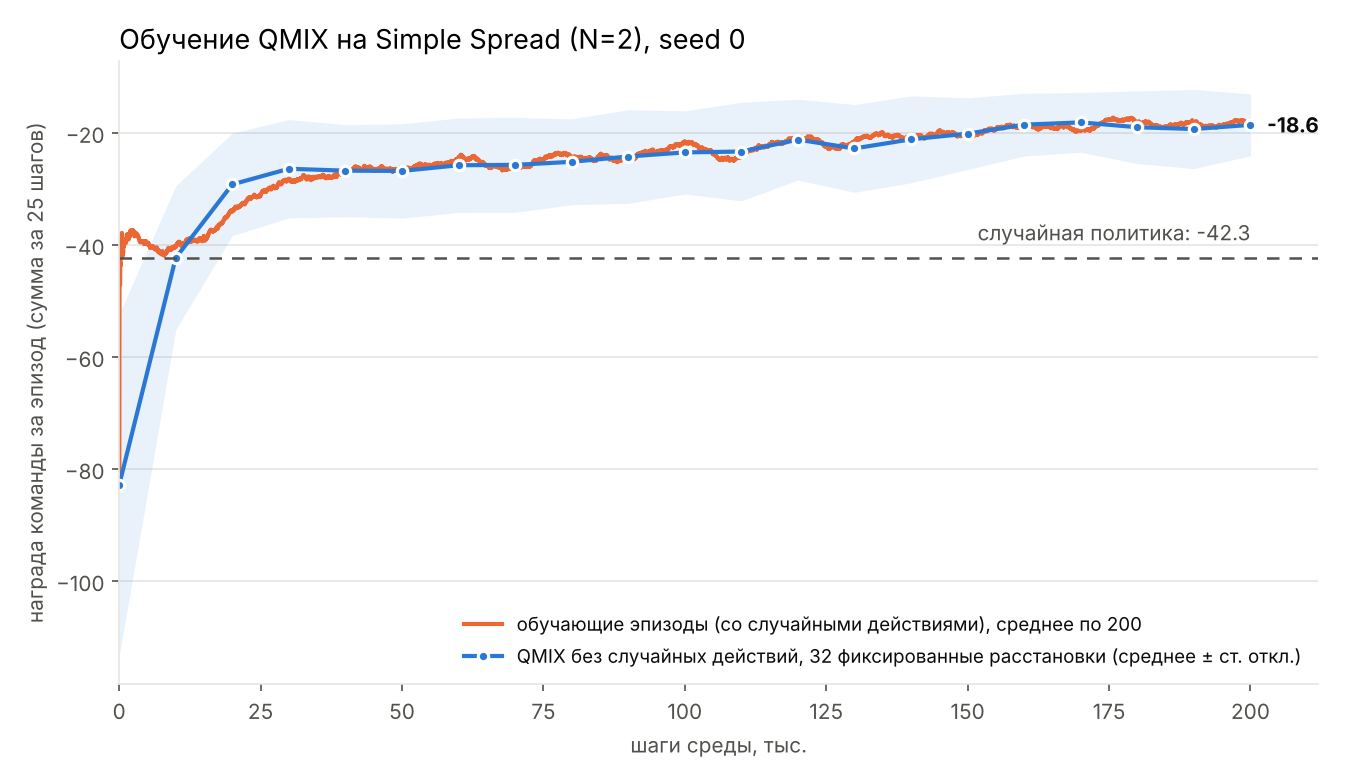

In [16]:
OUTPUT_ROOT = REPO_DIR if not QUICK_CHECK else os.path.join(REPO_DIR, "quick_check")
random_returns = random_baseline(config, config.eval_seeds())  # same 32 start positions, random actions
paths = save_run(result, config, random_returns, OUTPUT_ROOT)
for key, path in paths.items():
    print(f"{key:>10}: {os.path.relpath(path, REPO_DIR)}")
display(Image(filename=str(paths["curve"])))

**Как читать график.** По горизонтали — шаги среды. По вертикали — награда команды за эпизод, то есть сумма 25 наград за шаги. Она отрицательная, ближе к нулю — лучше.

* **Синяя линия** — обученная на этот момент политика без случайных действий, на одних и тех же 32 начальных расстановках. Полоса — разброс (± стандартное отклонение) между расстановками.
* **Оранжевая линия** — обучающие эпизоды, скользящее среднее. Они хуже синей, потому что в них часть действий случайная (исследование).
* **Пунктир** — случайные агенты на тех же 32 расстановках.

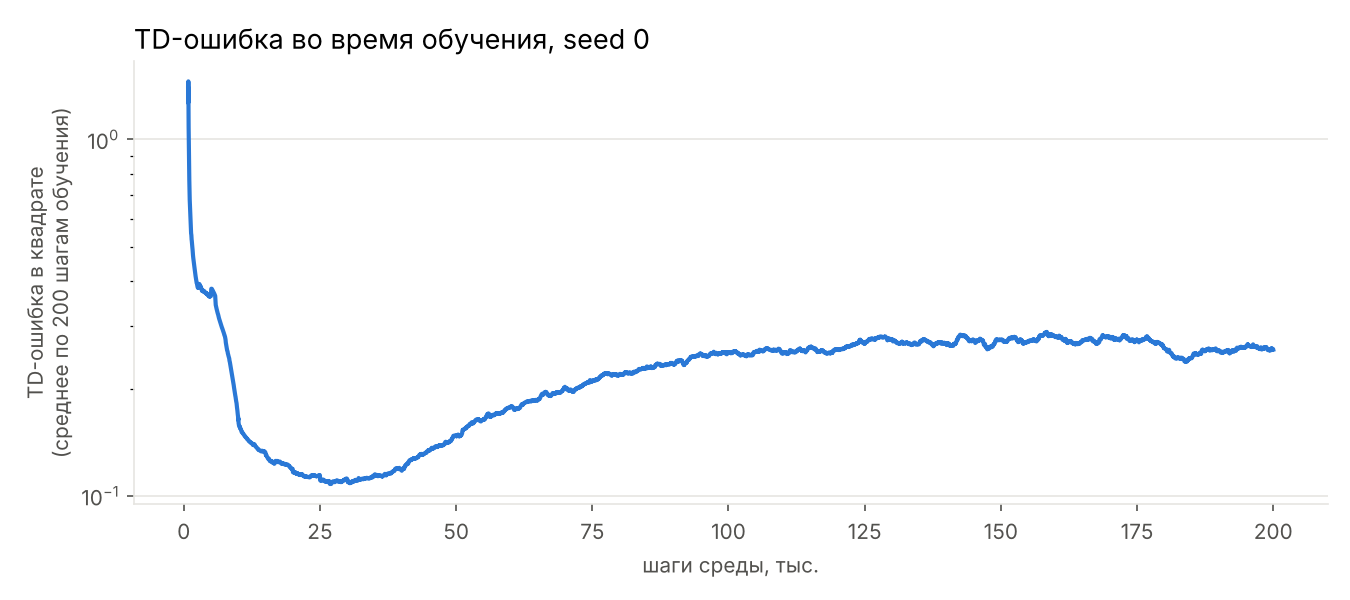

In [17]:
display(Image(filename=str(paths["loss"])))

## 10. Загрузка модели и эпизод без дообучения

Создаём новые сети, читаем веса из файла и проверяем, что загруженная модель отвечает теми же числами, что и модель в памяти. Затем проигрываем эпизод на начальной расстановке, которой не было ни в обучении, ни в оценках во время обучения (seed 30 000). Действия выбираются без случайности ($\varepsilon = 0$), градиентов и оптимизатора нет — это чистое выполнение политики.

In [18]:
loaded = load_checkpoint(paths["checkpoint"])
print("loaded:", os.path.relpath(paths["checkpoint"], REPO_DIR))
print("trained for", loaded.metadata["env_steps"], "env steps; created", loaded.metadata["created_utc"], "UTC")

reference = run_episode(env, QMIXPolicy(result.agent_net), seed=30_000)
reference_batch = episodes_to_batch([reference])
with torch.no_grad():
    q_in_memory = unroll_agent_network(result.agent_net, reference_batch["obs"], reference_batch["actions"])
    q_from_file = unroll_agent_network(loaded.agent_net, reference_batch["obs"], reference_batch["actions"])
print("largest difference of Q values, model in memory vs loaded from file:",
      (q_in_memory - q_from_file).abs().max().item())

loaded: models/qmix_spread_n2_seed0.pt
trained for 200000 env steps; created 2026-10-08 10:35:43 UTC
largest difference of Q values, model in memory vs loaded from file: 0.0


| шаг | действие агента 1 | действие агента 2 | награда команды |
| --- | --- | --- | --- |
| 1 | move_down | move_down | -1.020 |
| 2 | move_right | move_down | -0.999 |
| 3 | move_right | move_up | -0.994 |
| 4 | move_down | move_up | -0.923 |
| 5 | move_right | move_down | -0.797 |
| 6 | move_down | move_right | -0.706 |
| 7 | no_action | move_up | -0.578 |
| 8 | no_action | move_left | -0.443 |
| 9 | move_down | move_right | -0.358 |
| 10 | no_action | no_action | -0.247 |
| 11 | no_action | no_action | -0.184 |
| 12 | no_action | no_action | -0.162 |
| 13 | no_action | no_action | -0.168 |
| 14 | no_action | no_action | -0.184 |
| 15 | no_action | no_action | -0.201 |
| 16 | no_action | no_action | -0.215 |
| 17 | no_action | move_left | -0.228 |
| 18 | no_action | move_right | -0.189 |
| 19 | no_action | no_action | -0.208 |
| 20 | no_action | no_action | -0.222 |
| 21 | no_action | no_action | -0.234 |
| 22 | no_action | no_action | -0.242 |
| 23 | no_action | no_action | -0.248 |
| 24 | no_action | move_left | -0.253 |
| 25 | no_action | move_right | -0.207 |

QMIX:   episode return -10.21, average landmark-to-nearest-agent distance at the end 0.104
random: episode return -25.49, average landmark-to-nearest-agent distance at the end 0.344


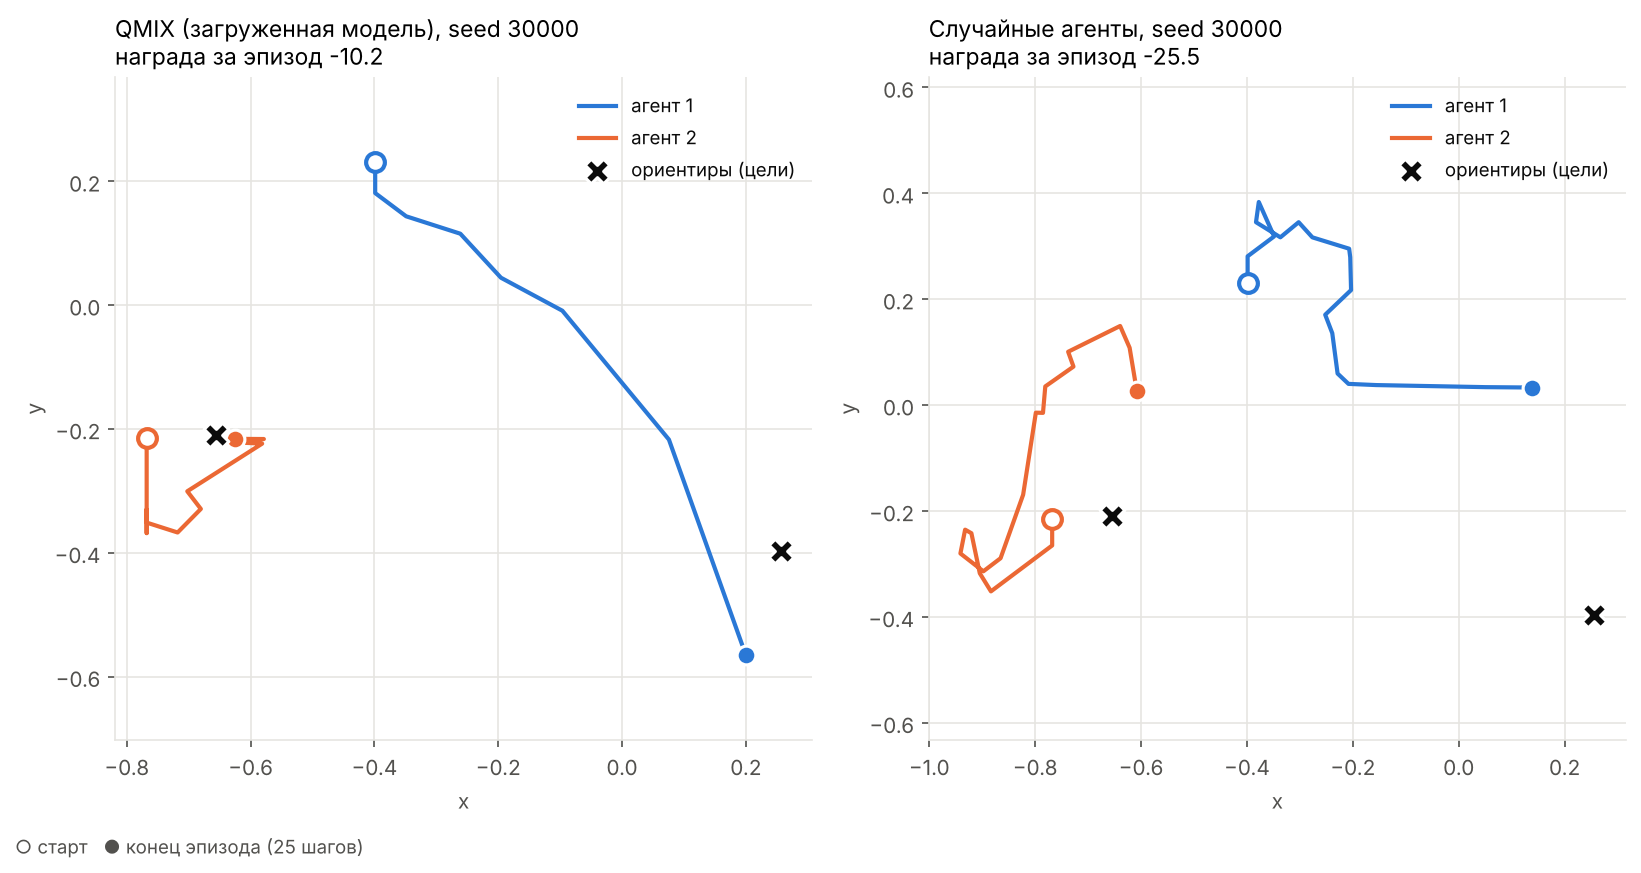

In [19]:
qmix_policy = QMIXPolicy(loaded.agent_net)  # only the agent network: decentralised execution
episode = run_episode(env, qmix_policy, seed=30_000, record_positions=True)
random_episode = run_episode(env, random_agents, seed=30_000, rng=np.random.default_rng(0), record_positions=True)

lines = ["| шаг | действие агента 1 | действие агента 2 | награда команды |", "| --- | --- | --- | --- |"]
for t in range(len(episode.rewards)):
    a1, a2 = episode.actions[t]
    lines.append(f"| {t + 1} | {ACTION_NAMES[a1]} | {ACTION_NAMES[a2]} | {episode.rewards[t]:.3f} |")
display(Markdown("\n".join(lines)))
print(f"QMIX:   episode return {episode.total_reward:.2f}, "
      f"average landmark-to-nearest-agent distance at the end {episode.final_mean_distance:.3f}")
print(f"random: episode return {random_episode.total_reward:.2f}, "
      f"average landmark-to-nearest-agent distance at the end {random_episode.final_mean_distance:.3f}")

trajectory_path = os.path.join(OUTPUT_ROOT, "results", "plots", "qmix_vs_random_episode_seed30000.png")
fig = plot_episode_trajectories(
    [(episode, "QMIX (загруженная модель), seed 30000"), (random_episode, "Случайные агенты, seed 30000")],
    trajectory_path,
)

**Проверка «модель лучше случайных агентов».** 100 начальных расстановок, которых не было при обучении (seed 30 000–30 099). Обе политики играют на одних и тех же расстановках. Это проверка для себя; официальное сравнение на своём наборе эпизодов делает Аслан.

In [20]:
check_seeds = list(range(30_000, 30_100))
qmix_check = evaluate(env, qmix_policy, check_seeds)
random_check = evaluate(env, random_agents, check_seeds, rng=np.random.default_rng(0))
difference = qmix_check - random_check  # paired: same start positions
standard_error = difference.std(ddof=1) / np.sqrt(len(difference))
print(f"QMIX:   mean {qmix_check.mean():.2f}, std {qmix_check.std():.2f}")
print(f"random: mean {random_check.mean():.2f}, std {random_check.std():.2f}")
print(f"QMIX better on {np.mean(difference > 0) * 100:.0f}% of the start positions")
print(f"mean difference {difference.mean():.2f} = {difference.mean() / standard_error:.1f} standard errors (criterion: > 5)")

QMIX:   mean -17.17, std 6.45
random: mean -41.00, std 13.34
QMIX better on 100% of the start positions
mean difference 23.83 = 22.4 standard errors (criterion: > 5)


## 11. Тот же TD-шаг на настоящем переходе обученной модели

Берём шаг 5 эпизода выше и пропускаем его через тот же код `QMIXLearner.compute_td_loss`, которым шло обучение. Видно $Q_i$ обоих агентов для всех действий, выбранные действия, $Q_{tot}$, награду, оценку следующего шага, TD-цель и ошибку. Потом делаем один шаг градиентного спуска только по этой ошибке (на копии модели, сама модель не меняется) и смотрим, как $Q_{tot}$ сдвинулась к TD-цели.

In [21]:
real = real_transition_example(loaded.agent_net, loaded.mixer, loaded.config, episode, step=5, lr=1e-4)
display(Markdown(format_real_example(real, ACTION_NAMES)))

| Шаг эпизода 5 | Значение |
| --- | --- |
| Q₁ для 5 действий (сеть агента 1) | [-0.907, -1.046, -0.878, -0.797, -1.178] |
| Q₂ для 5 действий (сеть агента 2) | [-1.209, -1.318, -1.151, -1.268, -1.211] |
| Выбранные действия | агент 1: move_down, агент 2: move_right |
| Q₁, Q₂ выбранных действий | -0.797, -1.151 |
| Q_tot (смешивающая сеть) | -3.8678 |
| Награда r | -0.7058 |
| Q лучших действий агентов в следующем шаге (выбирает обучаемая сеть, оценивает целевая) | -0.757, -1.159 |
| Q_tot′ следующего шага (целевая смешивающая сеть) | -3.9505 |
| TD-цель y = r + γ·Q_tot′ | -0.7058 + 0.95·(-3.9505) = -4.4588 |
| TD-ошибка δ = y − Q_tot | -0.5910 |
| Ошибка δ² | 0.349297 |
| Q_tot после одного шага градиентного спуска (шаг 0.0001) | -3.9874 |
| TD-ошибка после шага | -0.4714 |

**Таблица всех 25 совместных действий для этого шага у обученной модели.** Лучшее совместное действие снова совпадает с выбором агентов по отдельности.

In [22]:
with torch.no_grad():
    q_trained = unroll_agent_network(loaded.agent_net, episodes_to_batch([episode])["obs"],
                                     episodes_to_batch([episode])["actions"])[0, 5]  # [n, A] at step 5
state_5 = torch.as_tensor(episode.states[5]).unsqueeze(0)
table_md, best_joint = joint_action_table(q_trained, loaded.mixer, state_5)
display(Markdown(table_md))
print("best joint action:", [ACTION_NAMES[a] for a in best_joint],
      "| each agent's own best:", [ACTION_NAMES[int(a)] for a in q_trained.argmax(dim=1)])

| агент 1 \ агент 2 | no_action | move_left | move_right | move_down | move_up |
|---|---|---|---|---|---|
| no_action | -4.2773 | -4.5389 | -4.1348 | -4.4185 | -4.2811 |
| move_left | -4.6015 | -4.8568 | -4.4622 | -4.7392 | -4.6051 |
| move_right | -4.2087 | -4.4716 | -4.0655 | -4.3506 | -4.2125 |
| move_down | -4.0130 | -4.2797 | **-3.8678** | -4.1569 | -4.0168 |
| move_up | -4.9010 | -5.1507 | -4.7648 | -5.0357 | -4.9045 |

best joint action: ['move_down', 'move_right'] | each agent's own best: ['move_down', 'move_right']


## 12. Что получилось и кому передаётся

* **Аслану:** checkpoint `models/qmix_spread_n2_seed0.pt` и код запуска — в `models/README.md` (загрузка, оценка на своих seed, кадры эпизода для видео).
* **Дане:** этот notebook, график `results/plots/qmix_spread_n2_seed0_training_curve.png`, таблица числового примера (раздел 7) и пример на настоящем переходе (раздел 11).
* Все числа и версии — в `results/qmix_training_report.md` и `configs/qmix_spread_n2_seed0.json`.

В Colab файлы, созданные этим запуском, можно скачать одним архивом:

In [23]:
import zipfile

archive = os.path.join(OUTPUT_ROOT, "qmix_outputs.zip")
with zipfile.ZipFile(archive, "w") as zf:
    for path in [*paths.values(), paths["checkpoint"].with_suffix(".json"), trajectory_path]:
        zf.write(path, os.path.relpath(path, OUTPUT_ROOT))
print("archive:", os.path.relpath(archive, REPO_DIR))
try:
    from google.colab import files  # only exists in Colab

    files.download(archive)
except ImportError:
    print("not running in Colab: the files are already in the repository folders")

archive: qmix_outputs.zip
not running in Colab: the files are already in the repository folders
